# GB Transmission Network: HVDC, Offshore Wind, and Three Model Migrations

An 87-bus reduced model of the Great Britain transmission system, with LCC and VSC HVDC links
and offshore wind farms. It is small enough to need no licence, but until now it did not run:
three of the models its data named had moved on since the data was written, in three
different ways.

All three have been migrated. This notebook runs the result and checks it.

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import stepss

print('stepss', stepss.__version__)

plt.rcParams.update({
    'figure.figsize': (9, 4.2), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.6,
    'lines.linewidth': 1.8, 'font.size': 11, 'legend.frameon': False,
})
COL_1, COL_2, COL_3 = '#2a78d6', '#eb6834', '#1baf7a'


def run(data, dst, obs='obs.dat', tag='out'):
    """Assemble and run a case; return (ok, extractor_or_message)."""
    case = stepss.cfg()
    for f in data:
        case.addData(f)
    case.addDst(dst)
    case.addObs(obs)
    case.addTrj(f'{tag}.trj')
    case.addOut(f'{tag}.trace')
    case.addInit(f'{tag}_init.trace')
    try:
        stepss.sim().execSim(case)
        return True, stepss.extractor(case.getTrj())
    except Exception as err:
        msg = str(err).split('Last message was:')[-1].strip()
        if os.path.exists(f'{tag}.trace'):
            t = open(f'{tag}.trace', errors='replace').read()
            i = t.find('STOP CALL FROM')
            if i >= 0:
                msg += '\n' + '\n'.join(x for x in t[i:i + 200].splitlines() if x.strip())
        return False, msg

stepss 3.70


## The case

| File | Contents |
|---|---|
| `GBdyn.dat` | Network and dynamic data: 87 buses, synchronous machines, 9 `WT3` and 10 `WT4` wind farms |
| `GBhvdc.txt` | The HVDC links: 3 LCC and 4 VSC, as `TWOP` two-port records |
| `GBvoltrat.dat` | The solved operating point (`LFRESV` records) |
| `settings.dat`, `obs.dat` | Solver settings and observables |
| `nothing.dst`, `disturb.dst` | No-disturbance run, and a disturbance scenario |

In [2]:
for f in glob.glob('*.trj') + glob.glob('*.trace'):
    os.remove(f)

ok, res = run(['GBdyn.dat', 'GBhvdc.txt', 'GBvoltrat.dat', 'settings.dat'],
              'nothing.dst', tag='flat')
print('full case:', 'runs' if ok else 'blocked')
print('' if ok else res)

full case: runs



## The three migrations

Each is a different failure mode, and they need different reasoning. This is the useful part
of this notebook: the same symptom class ("the model does not work") had three distinct
causes.

### 1. A parameter list that grew: the wind farms

`WT3` and `WT4` still resolve by name, but the models behind them are now the **WECC
composite structure** (REPC_A plant control, REEC_A electrical control, REGC_A generator
interface, WTGT_A drivetrain, plus torque, pitch and aerodynamic blocks for WT3). They take
**128** and **103** parameters where the old records supplied 53.

The old records' first twelve fields were named in a header comment,
`Snom nturb Pnom Xeq Hg Ht Dtg Ktg R ratio p rho`. Five have a direct counterpart and were
carried across, the rating `SNOM` and the drivetrain `Ht`, `Hg`, `Dshaft`, `Kshaft`. The rest
described a physical machine that the block structure does not represent, so the control
blocks took WECC defaults.

### 2. A model registered under no name: the VSC links

`TWOP HVDC_VSC` is compiled into the engine but **registered under no name**, so no data file
can reach it. The registered VSC model is `HVDC_VSC_SC`, and it is not a rename: it takes 16
parameters against 19, and it is a self-commutating converter with a virtual synchronous
machine frequency loop.

Most of the list maps across. `Kpd`/`Kid` become `Kpp`/`Kip`, the same outer active-power PI
gains under new names. The old `alpha1`, `beta1`, `alpha2`, `beta2` characteristic
coefficients have no counterpart and were dropped. One gain is new, `Kwi`.

**`Kwi` was set to 0 deliberately.** It multiplies $(1 - \omega)$ in the outer active-power
loop, so zero leaves the converter on pure P/Q control, which is what these grid-following
links represented. Raising it makes them grid-forming, frequency-supporting devices. That is a
modelling decision, not a migration, so it is left for whoever wants it.

### 3. Parameters that moved into a controller: the LCC links

`TWOP HVDC_LCC` wanted 17 parameters where the records supplied 20. The first seventeen map
straight across in order; the three trailing values are `alphamin`, `Idred` and `gammamin`,
which are no longer user inputs because the `HVDC_LIM` discrete controller sets them.

In [3]:
print('--- a migrated VSC link ---')
txt = open('GBhvdc.txt').read()
i = txt.index('HVDC_VSC_SC')
print(txt[max(0, i - 200):i + 260])

--- a migrated VSC link ---
 BUSDC DC12   320.  ;
  BUSDC DC12IC   320.  ;
  
  LFRESV DC12   0.9821  0.  ;
  LFRESV DC12IC   0.974511  0.  ;   #0.9944766
  
  LINE HVDC12IC DC12  DC12IC 3.025 0.00 0.00 1000.0 1  ; 
  
  # TWOP HVDC_VSC_SC <name> <bus1> <bus2> <S/A> FP FQ P Q (origin) FP FQ P Q (extremity)
#   R L Hdc Snom Pnom Kp Ki Kpp Kip Kwi Kpq Kiq Kpw Kiw Vs1 Vs2
  TWOP  HVDC_VSC_SC  12VSC  12  DC12  A
      0.  0.  -500.0  0.   0.  0.  500.  0.
      0.01  0.2  0.03024  1110  


## Validation: does the case hold its operating point?

A dynamic model initialises from the power-flow solution, so with no disturbance every bus
should stay at its `LFRESV` voltage and every machine at its dispatched power. Drift here
would mean the migrated parameters are internally inconsistent.

In [4]:
buses = ['22', '5', '26', '27', '12']
print(f'{"bus":>5} {"V at t=0":>10} {"V final":>10} {"span":>11}   verdict')
for b in buses:
    v = res.getBus(b).mag
    span = float(np.ptp(v.value))
    print(f'{b:>5} {v.value[0]:10.5f} {v.value[-1]:10.5f} {span:11.2e}   '
          f'{"steady" if span < 2e-3 else "MOVES"}')

print(f'\n{"wind farm":>12} {"P at t=0":>10} {"P final":>10} {"rotor speed":>12}')
for w in ['WF3G1.05', 'WF3G2.05', 'WF3G3.05']:
    inj = res.getInj(w)
    print(f'{w:>12} {inj.Pe.value[0]:10.5f} {inj.Pe.value[-1]:10.5f} '
          f'{inj.wg.value[0]:12.5f}')

  bus   V at t=0    V final        span   verdict
   22    0.96691    0.96708    1.87e-04   steady
    5    0.98698    0.98800    1.03e-03   steady
   26    0.97506    0.97525    2.32e-04   steady
   27    0.97272    0.97292    2.79e-04   steady
   12    0.98213    0.98232    1.87e-04   steady

   wind farm   P at t=0    P final  rotor speed
    WF3G1.05    0.60371    0.60372      0.86260
    WF3G2.05    0.75689    0.75691      0.96982
    WF3G3.05    0.75362    0.75364      0.96754


Every bus holds its power-flow voltage and every wind farm holds its dispatched power. The
rotor speeds sit below 1.0 pu, which is correct for turbines operating below rated wind: the
WECC torque controller sets speed from a power-speed lookup, so a partly loaded machine runs
slow.

Bus 5 moves slightly more than the others. That is the HVDC1 converter control settling into
its own equilibrium, and it lands about 0.001 pu from the power-flow value within a fraction
of a second rather than drifting.

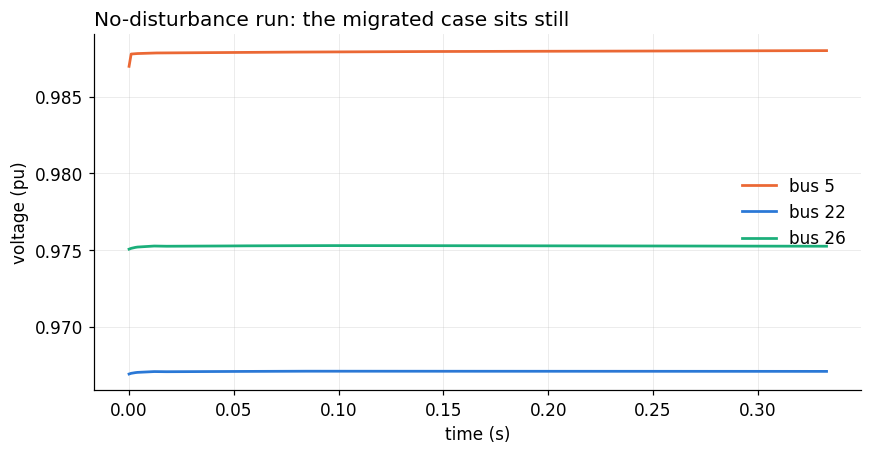

In [5]:
fig, ax = plt.subplots()
for b, colr in zip(['5', '22', '26'], [COL_2, COL_1, COL_3]):
    v = res.getBus(b).mag
    ax.plot(v.time, v.value, color=colr, label=f'bus {b}')
ax.set_xlabel('time (s)')
ax.set_ylabel('voltage (pu)')
ax.set_title('No-disturbance run: the migrated case sits still', loc='left')
ax.legend(loc='center right')
plt.show()

## A longer run

`disturb.dst` as distributed is a **template**: every event in it is commented out, leaving
only the solver directive and a 180 s `STOP`. That makes it a much longer flat run than the
one above, which is a stronger check that nothing in the migrated model drifts slowly.

In [6]:
print(open('disturb.dst').read())
ok_d, res_d = run(['GBdyn.dat', 'GBhvdc.txt', 'GBvoltrat.dat', 'settings.dat'],
                  'disturb.dst', tag='dist')
print('180 s run:', 'ok' if ok_d else 'failed')
print('' if ok_d else res_d)

 0.000 CONTINUE SOLVER BD 0.020 0.001 0. ABL
 
 # time.000 BREAKER BRANCH name 0 0					#Trip line
 
 # 3.000 BREAKER SYNC_MACH CCGTG16.01 0				#Trip sync machine 
 
 # time.000 BREAKER INJ name 0 						#Trip injector
 
 # 30.000 FAULT BUS 26 3.5 0. 						#3-ph short circuit (R to GND)
 # 30.100 CLEAR BUS 26
  
 # 40.000 CHGPRM TWOP HVDC2 inv_ctl -1. 0			#Chnage Parameter
 
 # time.000 VFAULT BUS name 0.5             		#3-ph shoirt circuit (V reached) 
 # time.100 CLEAR BUS name
 
180. STOP



180 s run: ok



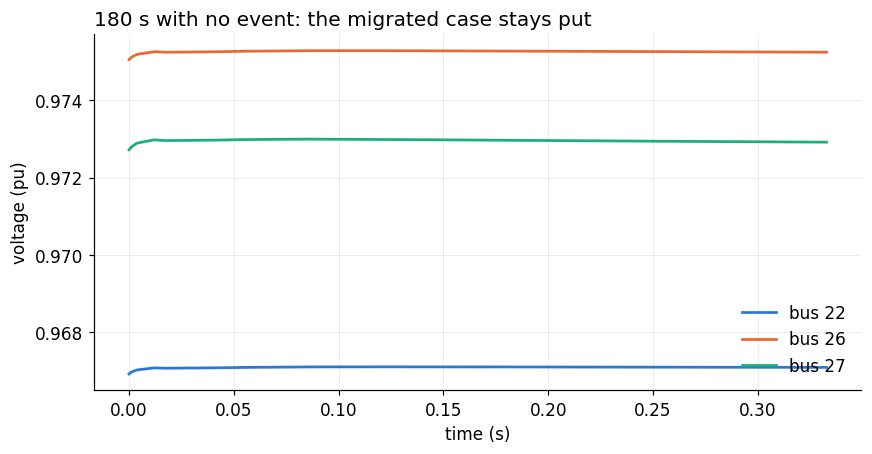

In [7]:
if ok_d:
    fig, ax = plt.subplots()
    for b, colr in zip(['22', '26', '27'], [COL_1, COL_2, COL_3]):
        v = res_d.getBus(b).mag
        ax.plot(v.time, v.value, color=colr, label=f'bus {b}')
    ax.set_xlabel('time (s)')
    ax.set_ylabel('voltage (pu)')
    ax.set_title('180 s with no event: the migrated case stays put', loc='left')
    ax.legend(loc='lower right')
    plt.show()

## A note on `analysis.ipynb`

The other notebook in this folder still does not run, for a reason unrelated to any of the
above: it loads `dyn_A.dat`, `volt_rat_A.dat` and `settings1.dat`, which are the **Nordic**
test system's filenames and do not exist here, and it calls `plt.grid(b=True, ...)`, a keyword
removed in Matplotlib 3.5. It looks like a copy of the Nordic tutorial that was never adapted.

In [8]:
import json

nb = json.load(open('analysis.ipynb'))
referenced = {tok for c in nb['cells'] for line in ''.join(c['source']).splitlines()
              for tok in line.split("'") if tok.endswith(('.dat', '.trj'))}
print('files referenced by analysis.ipynb:')
for f in sorted(referenced):
    print(f'  {f:20} {"present" if os.path.exists(f) else "MISSING"}')

files referenced by analysis.ipynb:
  dyn_A.dat            MISSING
  settings1.dat        MISSING
  volt_rat_A.dat       MISSING


## What you have seen

- **Three model failures with three different causes**, and why telling them apart matters: a
  grown parameter list needs a value migration, an unregistered model needs a different model
  chosen deliberately, and parameters that moved into a controller just need dropping.
- A migration validated by **running the case flat** and confirming it does not move, which is
  the cheapest strong test that a set of migrated parameters is self-consistent.
- One decision left explicit rather than defaulted: `Kwi = 0` keeps these HVDC links
  grid-following, and changing it changes what the test system represents.

### Things to try

- **Uncomment an event.** `disturb.dst` carries ready-made templates for a line trip, a
  machine trip, a bus fault and an HVDC control change. Uncomment one and rerun.
- **Make the links grid-forming.** Raise `Kwi` in `GBhvdc.txt` and repeat with a fault applied:
  the converters will then respond to frequency as if they had inertia.
- **Compare WT3 and WT4.** This system has both. `WT4` is the full-converter machine, with no
  torque, pitch or aerodynamic blocks, so its rotor is decoupled from the grid.
- **Rewrite `analysis.ipynb`** against this system's own filenames, using this notebook's
  `run()` helper.

### References

- [STEPSS model documentation](https://stepss.sps-lab.org/models/), for the WT3, WT4,
  HVDC_LCC and HVDC_VSC_SC parameter lists
- [stepss Python API](https://stepss.sps-lab.org/python/)